## 1. Imports and Paths

In [46]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer

DATA_PATH   = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/clean_ml_ready_10hz_expanded.csv")
PROJECT_DIR = DATA_PATH.parents[1]
RUN_NAME  = "run_v1" 
EDA_DIR   = PROJECT_DIR / "eda_outputs" / RUN_NAME
SPLIT_DIR = EDA_DIR / "splits"
for d in [EDA_DIR, SPLIT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", df.shape)
print("Flights:", df["log_id"].nunique())
print(df["dataset_label"].value_counts())
display(df.head())

Shape: (1019991, 378)
Flights: 172
dataset_label
normal      719371
abnormal    300620
Name: count, dtype: int64


,log_id,dataset_label,time_td,actuator_outputs__noutputs,actuator_outputs__output[0],actuator_outputs__output[1],actuator_outputs__output[2],actuator_outputs__output[3],actuator_outputs__output[4],actuator_outputs__output[5],...,vehicle_status__usb_connected,vehicle_status__open_drone_id_system_present,vehicle_status__open_drone_id_system_healthy,vehicle_status__parachute_system_present,vehicle_status__parachute_system_healthy,vehicle_status__avoidance_system_required,vehicle_status__avoidance_system_valid,vehicle_status__rc_calibration_in_progress,vehicle_status__calibration_enabled,vehicle_status__pre_flight_checks_pass
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Dataset Overview

In [47]:
dataset_summary = pd.DataFrame({
    "Metric": [
        "Total rows", "Total columns", "Unique flight logs",
        "Normal flights", "Abnormal flights", "Sampling rate"
    ],
    "Value": [
        df.shape[0], df.shape[1], df["log_id"].nunique(),
        df[df["dataset_label"]=="normal"]["log_id"].nunique(),
        df[df["dataset_label"]=="abnormal"]["log_id"].nunique(),
        "10 Hz (0.1s per row)"
    ]
})
display(dataset_summary)

,Metric,Value
0,Total rows,1019991
1,Total columns,378
2,Unique flight logs,172
3,Normal flights,129
4,Abnormal flights,43
5,Sampling rate,10 Hz (0.1s per row)


## 3. Define Target and Feature Lists

In [48]:
target_col       = "target_energy_next_60s_wh"
non_feature_cols = ["log_id", "dataset_label", "time_td"]
leakage_cols     = [
    "target_energy_next_60s_wh",
    "future_cumulative_energy_wh",
    "future_remaining_60s",
    "target_remaining_drop_60s"
]
cols_to_exclude = non_feature_cols + leakage_cols

allowed_core_features = [
    "time_s",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__current_average_a",
    "battery_status__remaining",
    "battery_status__discharged_mah",
    "power_w",
    "energy_increment_wh",
    "cumulative_energy_wh"
]

print("Target:", target_col, "| exists:", target_col in df.columns)
print("\nCore features available:")
for col in allowed_core_features:
    print(f"  {col}: {col in df.columns}")

Target: target_energy_next_60s_wh | exists: True

Core features available:
  time_s: True
  battery_status__voltage_v: True
  battery_status__voltage_filtered_v: True
  battery_status__current_a: True
  battery_status__current_filtered_a: True
  battery_status__current_average_a: True
  battery_status__remaining: True
  battery_status__discharged_mah: True
  power_w: True
  energy_increment_wh: True
  cumulative_energy_wh: True


## 4. Outlier Detection (normal flights only)

In [49]:
#to find normal flights with suspiciously high target values
THRESHOLD = 20  # Wh — physically implausible for a normal 60s window

normal_df   = df[df["dataset_label"] == "normal"].copy()
high_energy = normal_df[normal_df[target_col] > THRESHOLD]

print(f"Rows with target > {THRESHOLD} Wh in NORMAL flights: {len(high_energy):,}")
print(f"  = {100 * len(high_energy) / len(normal_df):.3f}% of normal rows\n")

flight_summary = (
    high_energy.groupby("log_id")
    .agg(
        n_high_rows=(target_col, "count"),
        max_target=(target_col, "max"),
        mean_target=(target_col, "mean"),
        p95_target=(target_col, lambda x: x.quantile(0.95)),
        mean_power=("power_w", "mean")
    )
    .sort_values("max_target", ascending=False)
    .reset_index()
)

print(f"Flights affected: {len(flight_summary)} / {normal_df['log_id'].nunique()} normal flights\n")
print(flight_summary.to_string(index=False))

Rows with target > 20 Wh in NORMAL flights: 22,062
  = 3.067% of normal rows

Flights affected: 1 / 129 normal flights

                              log_id  n_high_rows  max_target  mean_target  p95_target  mean_power
e68d22d7-7b96-4767-a074-edfca1c7f78c        22062   66.087665    52.342273   55.178231 3133.123001


## 5. Time series plot of suspect flights

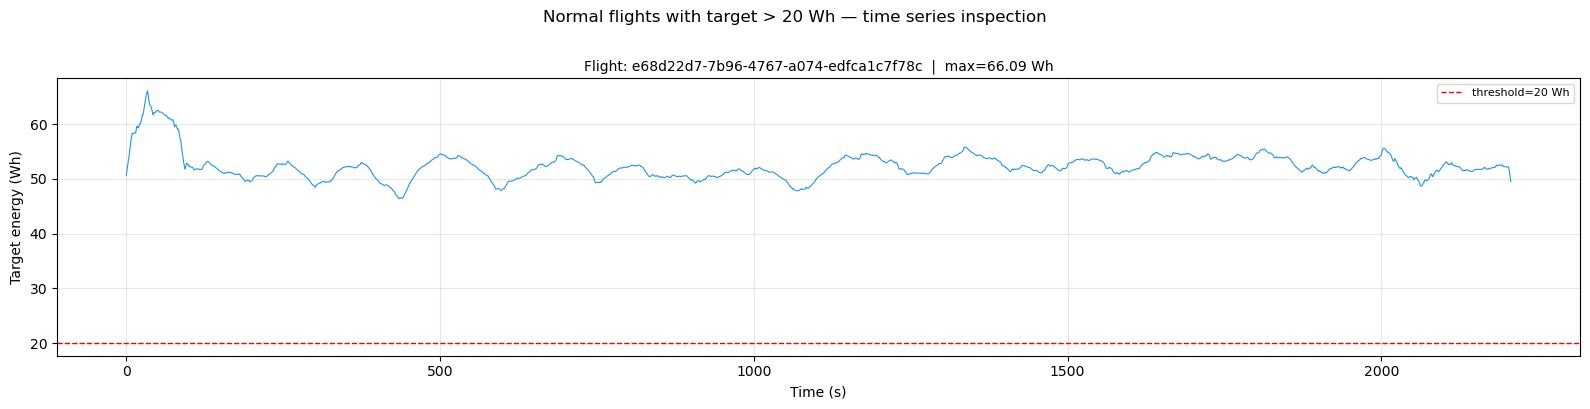

In [50]:
suspect_flights = flight_summary["log_id"].tolist()
n_plots = min(4, len(suspect_flights))

fig, axes = plt.subplots(n_plots, 1, figsize=(16, 4 * n_plots))
if n_plots == 1:
    axes = [axes]

for ax, fid in zip(axes, suspect_flights[:4]):
    fd = normal_df[normal_df["log_id"] == fid].sort_values("time_s")
    ax.plot(fd["time_s"], fd[target_col], linewidth=0.8, color="#2196F3")
    ax.axhline(THRESHOLD, color="red", linestyle="--", linewidth=1,
               label=f"threshold={THRESHOLD} Wh")
    ax.set_title(f"Flight: {fid}  |  max={fd[target_col].max():.2f} Wh", fontsize=10)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Target energy (Wh)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle("Normal flights with target > 20 Wh — time series inspection",
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_timeseries_suspect_flights.png",
            dpi=150, bbox_inches="tight")
plt.show()

## 6. IQR and Z-score statistical confirmation

IQR Method
  Q1=0.2779  Q3=3.0706  IQR=2.7926
  Outlier upper bound (Q3+3xIQR): 11.4485 Wh
  Rows above threshold: 22,062

Z-score Method (|z|>3)
  Rows flagged: 22,062

Percentile Breakdown
  p90: 3.6068 Wh
  p95: 5.3111 Wh
  p99: 53.0762 Wh
  p99.5: 54.0081 Wh
  p99.9: 58.3473 Wh
  p100: 66.0877 Wh


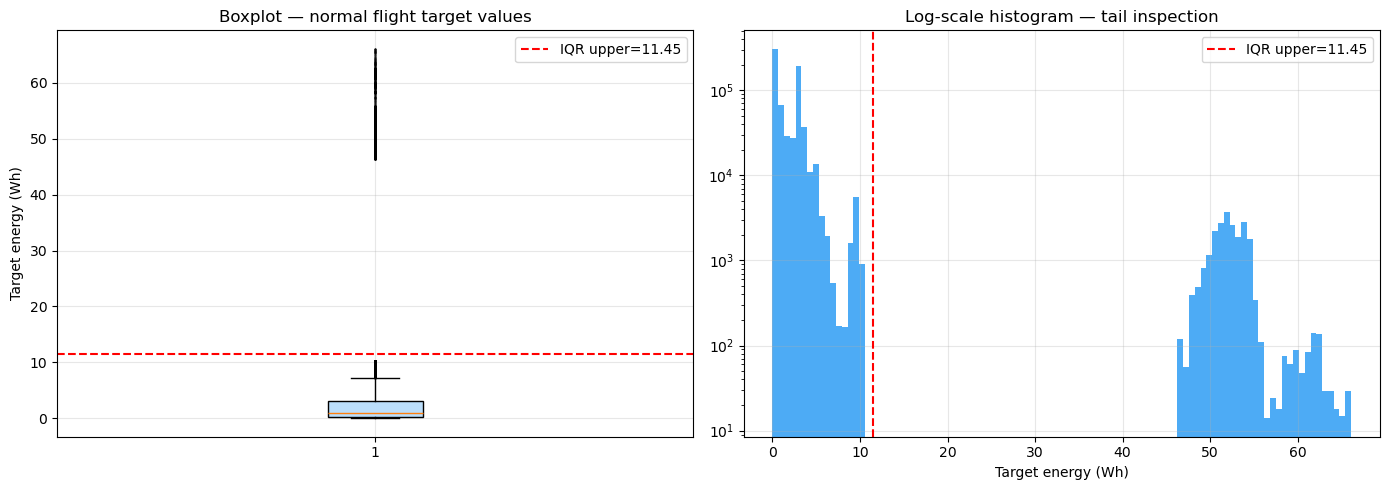

In [51]:
target_vals = normal_df[target_col].dropna()
Q1, Q3 = target_vals.quantile(0.25), target_vals.quantile(0.75)
IQR = Q3 - Q1
iqr_upper = Q3 + 3 * IQR
z_scores = np.abs(stats.zscore(target_vals))

print("IQR Method")
print(f"  Q1={Q1:.4f}  Q3={Q3:.4f}  IQR={IQR:.4f}")
print(f"  Outlier upper bound (Q3+3xIQR): {iqr_upper:.4f} Wh")
print(f"  Rows above threshold: {(target_vals > iqr_upper).sum():,}")
print("\nZ-score Method (|z|>3)")
print(f"  Rows flagged: {(z_scores > 3).sum():,}")
print("\nPercentile Breakdown")
for p in [90, 95, 99, 99.5, 99.9, 100]:
    print(f"  p{p}: {np.percentile(target_vals, p):.4f} Wh")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.boxplot(target_vals, vert=True, patch_artist=True,
            boxprops=dict(facecolor="#BBDEFB"),
            flierprops=dict(marker=".", markersize=1, alpha=0.3))
ax1.axhline(iqr_upper, color="red", linestyle="--",
            label=f"IQR upper={iqr_upper:.2f}")
ax1.set_title("Boxplot — normal flight target values")
ax1.set_ylabel("Target energy (Wh)")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.hist(target_vals, bins=100, color="#2196F3", alpha=0.8,
         edgecolor="none", log=True)
ax2.axvline(iqr_upper, color="red", linestyle="--",
            label=f"IQR upper={iqr_upper:.2f}")
ax2.set_title("Log-scale histogram — tail inspection")
ax2.set_xlabel("Target energy (Wh)")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_iqr_zscore_test.png", dpi=150)
plt.show()

## 7. Power vs target scatter (confirm it's a different aircraft)

Top 20 high-target rows:
                              log_id  time_s   power_w  energy_increment_wh  cumulative_energy_wh  target_energy_next_60s_wh
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.6 3593.2422             0.099812             23.708082                  66.087665
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.7 3593.2422             0.099812             23.807894                  66.071539
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.8 3387.1223             0.094087             23.901981                  66.061138
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.5 3226.6917             0.089630             23.608269                  66.060095
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.9 3387.1223             0.094087             23.996067                  66.026597
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.4 3226.6917             0.089630             23.518639                  66.022343
e68d22d7-7b96-4767-a074-edfca1c7f78c    34.0 3477.0989             0.096586             24.092653   

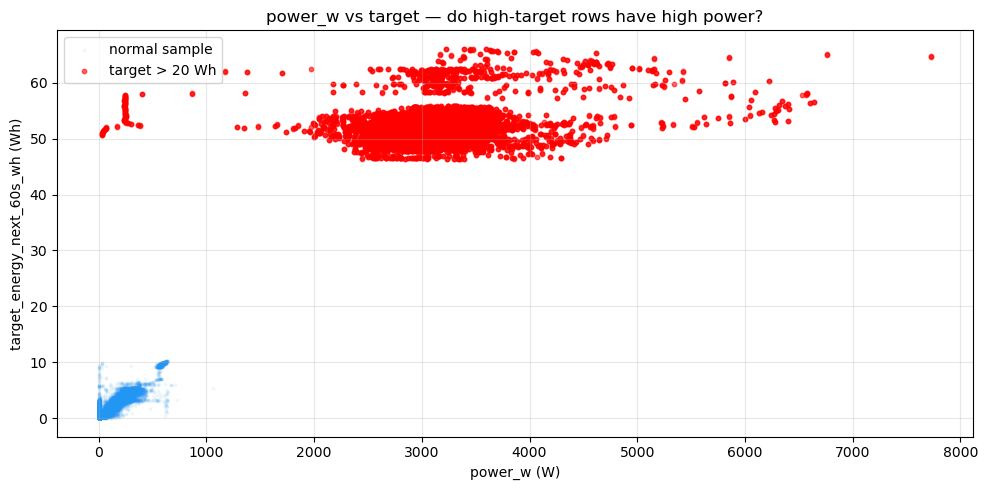

In [52]:
high_rows = normal_df[normal_df[target_col] > THRESHOLD][
    ["log_id", "time_s", "power_w", "energy_increment_wh",
     "cumulative_energy_wh", target_col]
].sort_values(target_col, ascending=False)

print("Top 20 high-target rows:")
print(high_rows.head(20).to_string(index=False))
print(f"\n  mean power_w (outlier rows)  : {high_rows['power_w'].mean():.2f} W")
print(f"  max  power_w (outlier rows)  : {high_rows['power_w'].max():.2f} W")
print(f"  Normal fleet mean power_w    : {normal_df['power_w'].mean():.2f} W")
print(f"  Normal fleet p99 power_w     : {normal_df['power_w'].quantile(0.99):.2f} W")

fig, ax = plt.subplots(figsize=(10, 5))
sample = normal_df.sample(min(50000, len(normal_df)), random_state=42)
ax.scatter(sample["power_w"], sample[target_col],
           alpha=0.05, s=3, color="#2196F3", label="normal sample")
ax.scatter(high_rows["power_w"], high_rows[target_col],
           alpha=0.6, s=10, color="red", label=f"target > {THRESHOLD} Wh")
ax.set_xlabel("power_w (W)")
ax.set_ylabel("target_energy_next_60s_wh (Wh)")
ax.set_title("power_w vs target — do high-target rows have high power?")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_power_vs_target.png", dpi=150)
plt.show()

## 8. Remove outlier flight and update both df and normal_df

In [53]:
before_shape   = df.shape
before_flights = df["log_id"].nunique()

suspect_flights = flight_summary["log_id"].dropna().unique().tolist()
df        = df[~df["log_id"].isin(suspect_flights)].copy()
normal_df = df[df["dataset_label"] == "normal"].copy()  # refresh after removal

print("Before:", before_shape)
print("After :", df.shape)
print("Flights removed:", before_flights - df["log_id"].nunique())
print("Suspect flights:", suspect_flights)

Before: (1019991, 378)
After : (997929, 378)
Flights removed: 1
Suspect flights: ['e68d22d7-7b96-4767-a074-edfca1c7f78c']


## 9. Temporal gap check

In [54]:
expected_gap = 0.1
allowed_gap  = 0.15

df_sorted          = df.sort_values(["log_id", "time_s"]).copy()
df_sorted["time_gap"] = df_sorted.groupby("log_id")["time_s"].diff()
time_gaps          = df_sorted["time_gap"].dropna()

gap_summary = pd.DataFrame({
    "Check": [
        "Expected gap for 10 Hz data",
        "Average observed gap",
        "Median observed gap",
        "Smallest observed gap",
        "Largest observed gap",
        "Total time gaps checked",
        "Number of gaps above allowed limit",
        "Percentage of large gaps"
    ],
    "Result": [
        expected_gap,
        round(time_gaps.mean(), 6),
        round(time_gaps.median(), 6),
        round(time_gaps.min(), 6),
        round(time_gaps.max(), 6),
        len(time_gaps),
        (time_gaps > allowed_gap).sum(),
        round((time_gaps > allowed_gap).mean() * 100, 4)
    ]
})
display(gap_summary)

,Check,Result
0,Expected gap for 10 Hz data,0.100000
1,Average observed gap,0.100245
2,Median observed gap,0.100000
3,Smallest observed gap,0.100000
4,Largest observed gap,6.700000
5,Total time gaps checked,997758.000000
6,Number of gaps above allowed limit,411.000000
7,Percentage of large gaps,0.041200


## 10. Gap review by flight

In [55]:
gap_rows = df_sorted[df_sorted["time_gap"] > allowed_gap].copy()

gap_summary_by_flight = (
    gap_rows.groupby("log_id")
    .agg(
        number_of_gaps=("time_gap", "count"),
        max_gap_s=("time_gap", "max"),
        mean_gap_s=("time_gap", "mean"),
        first_gap_time_s=("time_s", "min"),
        last_gap_time_s=("time_s", "max")
    )
    .reset_index()
    .sort_values("max_gap_s", ascending=False)
)

display(gap_summary_by_flight.head(20))
print("Total flights with gaps:", gap_summary_by_flight["log_id"].nunique())
print("Total gap rows:", len(gap_rows))

,log_id,number_of_gaps,max_gap_s,mean_gap_s,first_gap_time_s,last_gap_time_s
36,5c1b7f3d-57d4-427e-b302-d22956f66f0b,1,6.7,6.700000,7.9,7.9
3,0332fefb-a16f-4ff9-b626-e8a158346ff4,30,2.5,0.980000,167.0,347.3
19,1b9a2fee-db24-4c6d-b88d-ac3950286eae,6,2.0,1.000000,33.7,317.8
7,06b760bf-d457-46b7-84e1-f08c180aefb3,1,2.0,2.000000,561.6,561.6
43,75678c0f-b911-4875-a2cf-bc317c489c22,8,2.0,1.000000,59.3,779.9
49,80bfac4b-fa67-4fc7-8833-7789229fb78f,6,1.5,1.000000,78.3,284.6
4,03a4237b-52e2-4327-8bfd-0f6e4d6de940,6,1.5,1.250000,29.0,308.2
37,66c5f92a-1fd2-4ddb-b9d8-aba8e1dfcacb,15,1.5,0.800000,27.1,776.4
8,08aab983-e7b7-41b0-a3fe-c719f68cc230,8,1.5,0.850000,1023.6,1089.1
30,4259190b-f88c-4416-b276-dd04d854e70f,4,1.5,0.850000,6.3,238.3


Total flights with gaps: 84
Total gap rows: 411


## 11. Remove flights with serious gaps

In [56]:
SERIOUS_GAP_THRESHOLD = 2.0

serious_gap_flights = gap_summary_by_flight[
    gap_summary_by_flight["max_gap_s"] > SERIOUS_GAP_THRESHOLD
]["log_id"].tolist()

print("Flights with serious gaps:", len(serious_gap_flights))
print(serious_gap_flights)

before_rows    = len(df)
before_flights = df["log_id"].nunique()

df = df[~df["log_id"].isin(serious_gap_flights)].copy()

print(f"Rows removed    : {before_rows - len(df):,}")
print(f"Flights removed : {before_flights - df['log_id'].nunique()}")
print(f"Remaining rows  : {len(df):,}")
print(f"Remaining flights: {df['log_id'].nunique()}")

Flights with serious gaps: 3
['5c1b7f3d-57d4-427e-b302-d22956f66f0b', '0332fefb-a16f-4ff9-b626-e8a158346ff4', '1b9a2fee-db24-4c6d-b88d-ac3950286eae']
Rows removed    : 26,107
Flights removed : 3
Remaining rows  : 971,822
Remaining flights: 168


## 12. Verify gaps are gone

In [57]:

df_sorted          = df.sort_values(["log_id", "time_s"]).copy()
df_sorted["time_gap"] = df_sorted.groupby("log_id")["time_s"].diff()
time_gaps_clean    = df_sorted["time_gap"].dropna()

print("Post-removal gap check:")
print(time_gaps_clean.describe().round(6))
print(f"Gaps > 0.15s : {(time_gaps_clean > 0.15).sum()}")
print(f"Gaps > 2.0s  : {(time_gaps_clean > 2.0).sum()}")

Post-removal gap check:
count    971654.000000
mean          0.100212
std           0.012461
min           0.100000
25%           0.100000
50%           0.100000
75%           0.100000
max           2.000000
Name: time_gap, dtype: float64
Gaps > 0.15s : 374
Gaps > 2.0s  : 0


## 13. Class imbalance chart

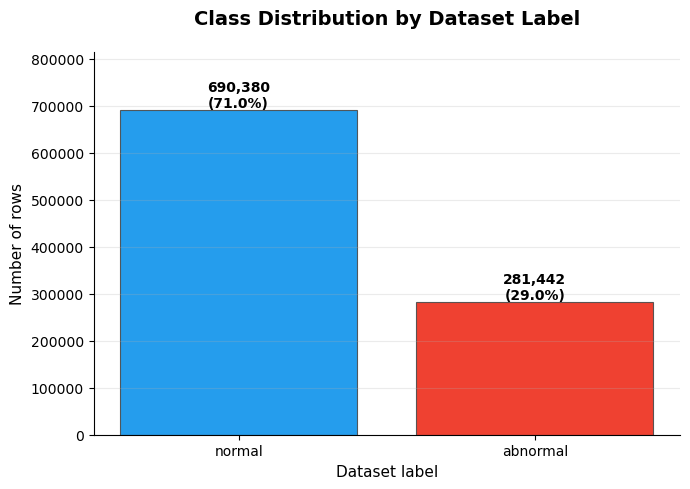

dataset_label
normal      690380
abnormal    281442
Name: count, dtype: int64


In [58]:
label_counts = df["dataset_label"].value_counts()
total_rows   = label_counts.sum()
percentages  = (label_counts / total_rows) * 100

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(label_counts.index, label_counts.values,
              color=["#0D93EC", "#EE2C1A"],
              edgecolor="#4A4A4A", linewidth=0.8, alpha=0.9)

for bar, count, pct in zip(bars, label_counts.values, percentages.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{count:,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_title("Class Distribution by Dataset Label", fontsize=14,
             fontweight="bold", pad=20)
ax.set_xlabel("Dataset label", fontsize=11)
ax.set_ylabel("Number of rows", fontsize=11)
ax.set_ylim(0, label_counts.max() * 1.18)
ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(EDA_DIR / "class_distribution.png", dpi=150)
plt.show()
print(label_counts)

## 14. Target distribution analysis

count    971822.0000
mean          2.3704
std           3.5056
min           0.0000
25%           0.2612
50%           1.4785
75%           3.1489
max          27.5020
Name: target_energy_next_60s_wh, dtype: float64

Skewness : 3.8799
Kurtosis : 19.1032


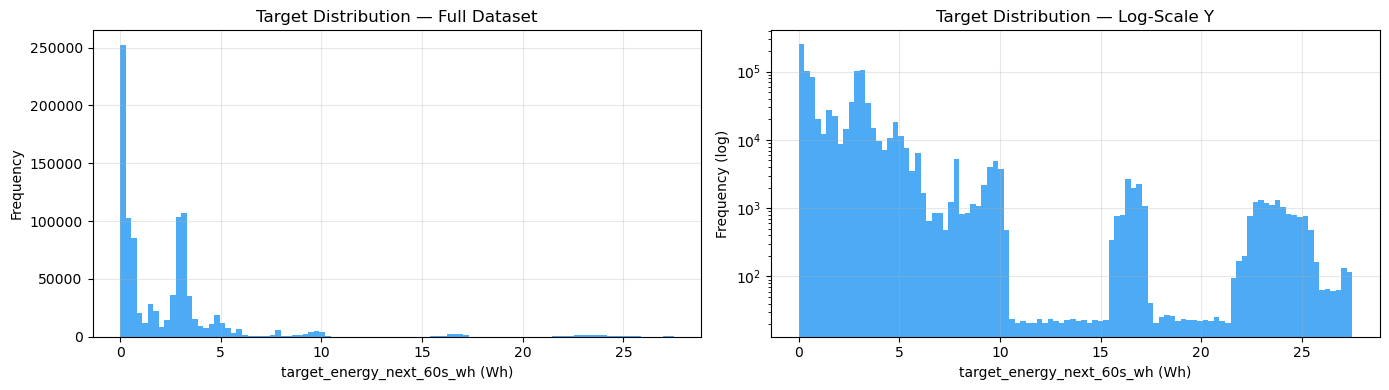

In [59]:

print(df[target_col].describe().round(4))
print(f"\nSkewness : {df[target_col].skew():.4f}")
print(f"Kurtosis : {df[target_col].kurt():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df[target_col], bins=100, color="#2196F3",
             alpha=0.8, edgecolor="none")
axes[0].set_title("Target Distribution — Full Dataset")
axes[0].set_xlabel("target_energy_next_60s_wh (Wh)")
axes[0].set_ylabel("Frequency")
axes[0].grid(alpha=0.3)

axes[1].hist(df[target_col], bins=100, color="#2196F3",
             alpha=0.8, edgecolor="none", log=True)
axes[1].set_title("Target Distribution — Log-Scale Y")
axes[1].set_xlabel("target_energy_next_60s_wh (Wh)")
axes[1].set_ylabel("Frequency (log)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(EDA_DIR / "target_distribution.png", dpi=150)
plt.show()

## 15. Target distribution: normal vs abnormal (3-panel)

normal: n=690,380  median=0.786  p99=9.225  max=10.309
abnormal: n=281,442  median=2.638  p99=24.689  max=27.502


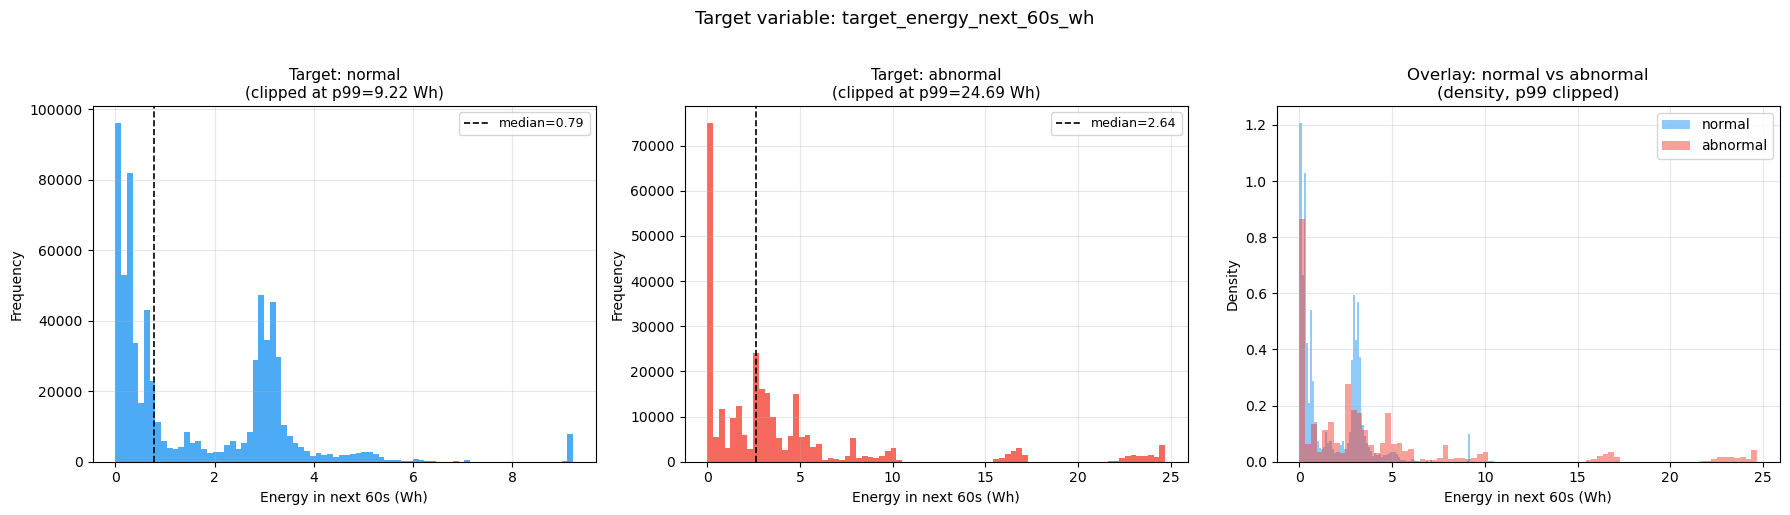

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {"normal": "#2196F3", "abnormal": "#F44336"}

for ax, label in zip(axes[:2], ["normal", "abnormal"]):
    subset  = df[df["dataset_label"] == label][target_col].dropna()
    p99     = np.percentile(subset, 99)
    clipped = subset.clip(upper=p99)
    print(f"{label}: n={len(subset):,}  median={subset.median():.3f}  "
          f"p99={p99:.3f}  max={subset.max():.3f}")
    ax.hist(clipped, bins=80, color=colors[label], alpha=0.8, edgecolor="none")
    ax.axvline(subset.median(), color="black", linestyle="--", linewidth=1.2,
               label=f"median={subset.median():.2f}")
    ax.set_title(f"Target: {label}\n(clipped at p99={p99:.2f} Wh)", fontsize=11)
    ax.set_xlabel("Energy in next 60s (Wh)")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

ax = axes[2]
for label in ["normal", "abnormal"]:
    subset = df[df["dataset_label"] == label][target_col].dropna()
    p99    = np.percentile(subset, 99)
    ax.hist(subset.clip(upper=p99), bins=80, alpha=0.5, label=label,
            color=colors[label], edgecolor="none", density=True)
ax.set_title("Overlay: normal vs abnormal\n(density, p99 clipped)")
ax.set_xlabel("Energy in next 60s (Wh)")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle("Target variable: target_energy_next_60s_wh",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(EDA_DIR / "target_distribution_clean.png",
            dpi=150, bbox_inches="tight")
plt.show()

## 16. Normal vs Abnormal feature distributions

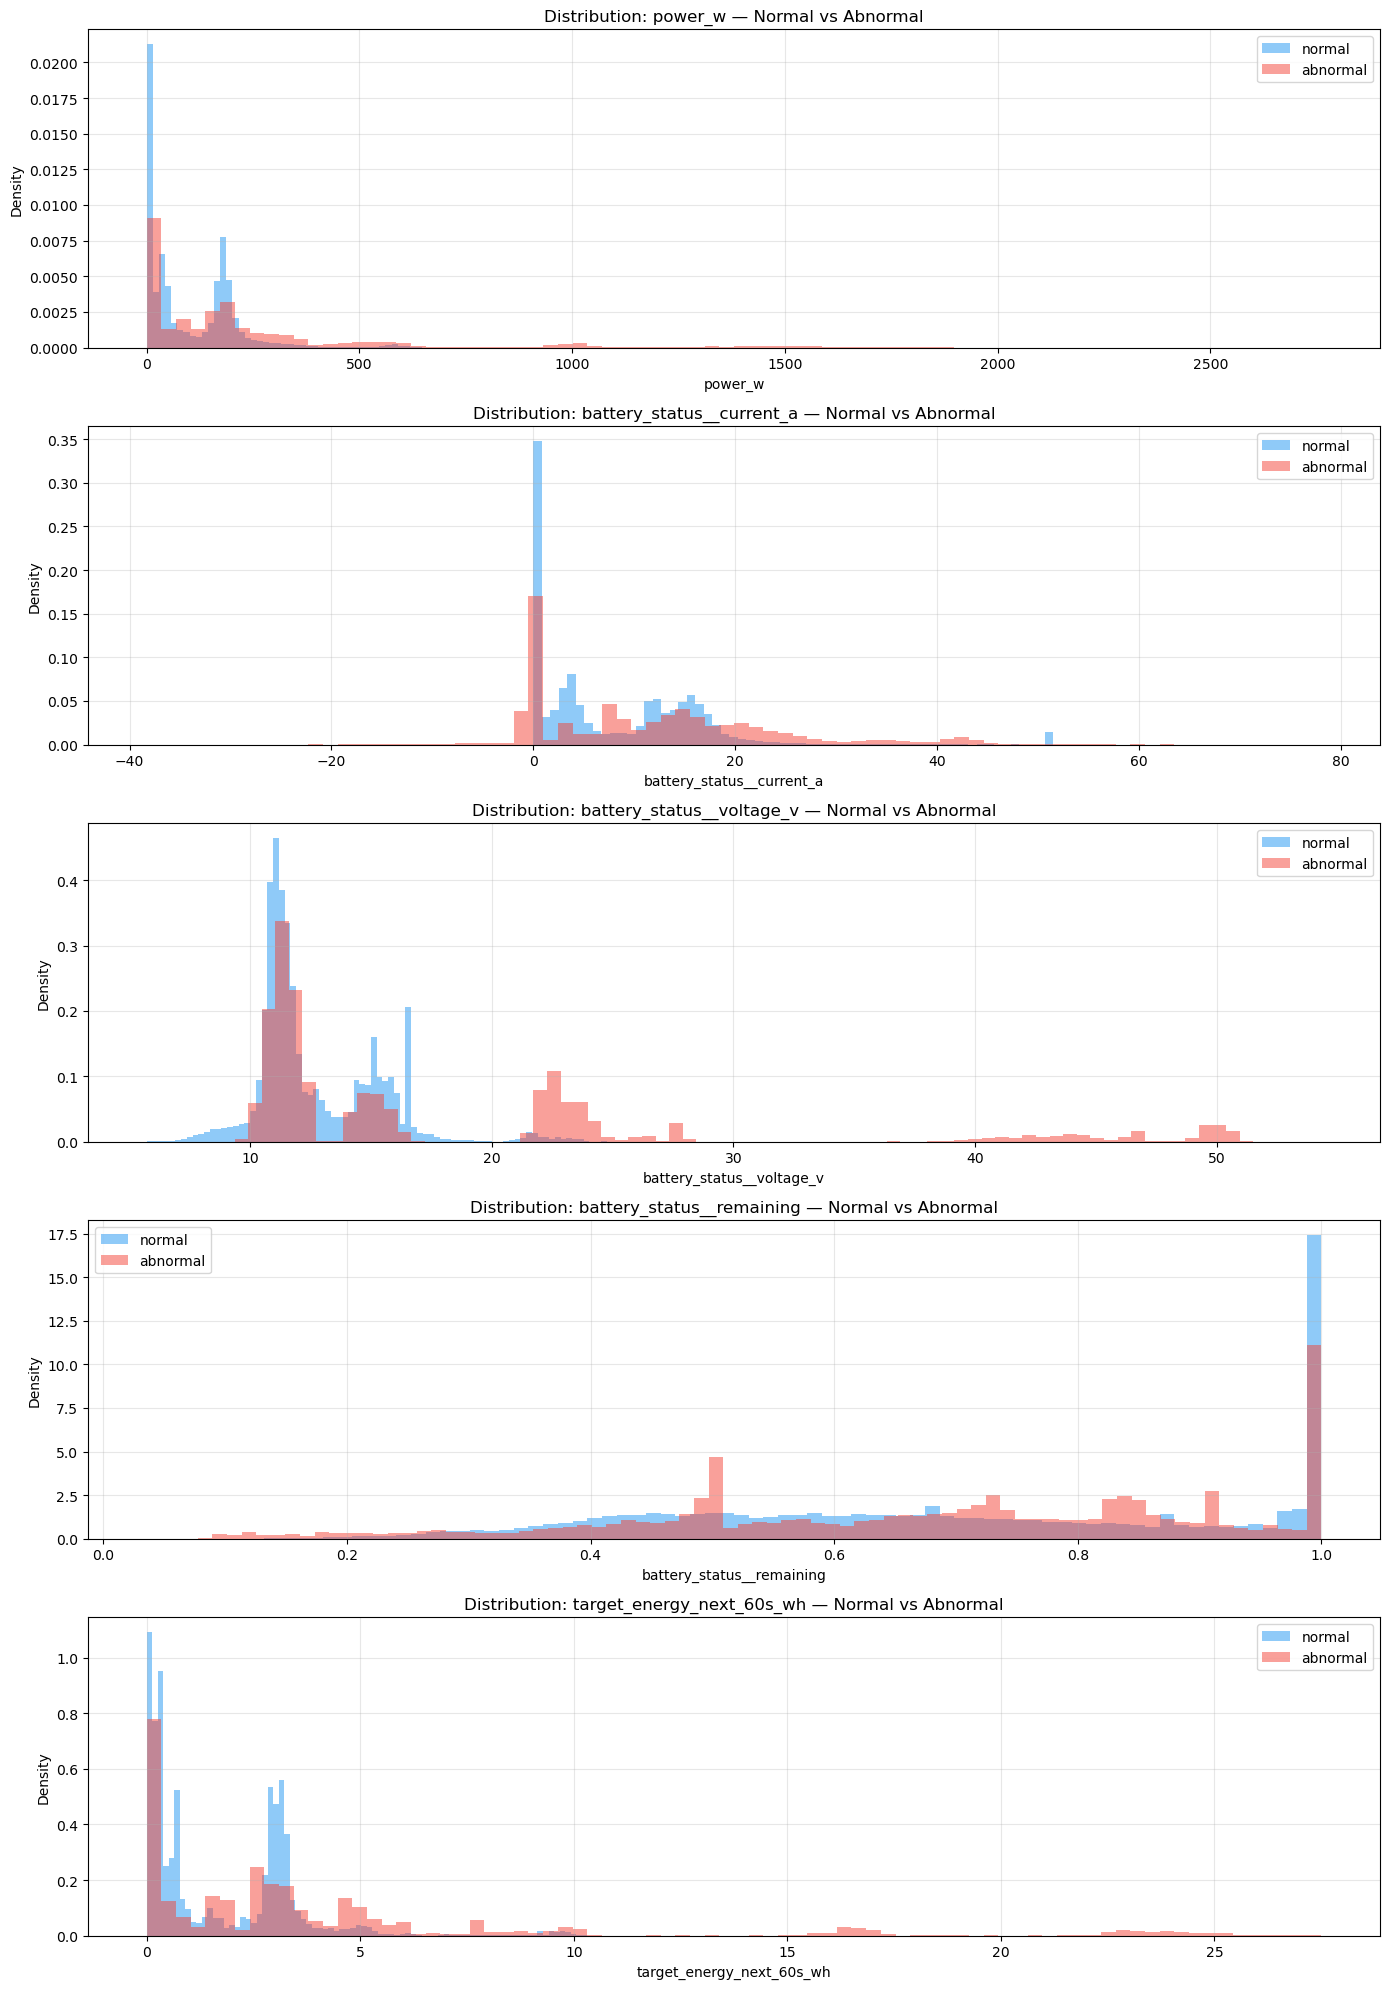


Median values — Normal vs Abnormal:
dataset_label              abnormal   normal
power_w                    150.9856  51.7438
battery_status__current_a    9.2087   4.6624
battery_status__voltage_v   12.3888  11.6405
battery_status__remaining    0.7111   0.6915
target_energy_next_60s_wh    2.6381   0.7862


In [61]:
compare_features = [
    "power_w", "battery_status__current_a",
    "battery_status__voltage_v",
    "battery_status__remaining", target_col
]
compare_features = [f for f in compare_features if f in df.columns]

fig, axes = plt.subplots(len(compare_features), 1,
                          figsize=(14, 4 * len(compare_features)))

for ax, feat in zip(axes, compare_features):
    for label, color in [("normal", "#2196F3"), ("abnormal", "#F44336")]:
        vals = df[df["dataset_label"] == label][feat].dropna()
        ax.hist(vals, bins=80, alpha=0.5, color=color,
                label=label, edgecolor="none", density=True)
    ax.set_title(f"Distribution: {feat} — Normal vs Abnormal")
    ax.set_xlabel(feat)
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(EDA_DIR / "normal_vs_abnormal_feature_distributions.png", dpi=150)
plt.show()

print("\nMedian values — Normal vs Abnormal:")
print(df.groupby("dataset_label")[compare_features].median().round(4).T.to_string())

## 17. Voltage range check (airframe difference evidence)

In [62]:
print("VOLTAGE RANGE BY LABEL")
for label in ["normal", "abnormal"]:
    v = df[df["dataset_label"] == label]["battery_status__voltage_v"]
    print(f"\n{label}:")
    print(f"  min={v.min():.2f}V  max={v.max():.2f}V  median={v.median():.2f}V")
    print(f"  Rows with voltage > 25V: {(v > 25).sum():,} ({100*(v>25).mean():.1f}%)")

#flight-level voltage summary
flight_voltage = (
    df.groupby(["log_id", "dataset_label"])
    .agg(
        max_voltage=("battery_status__voltage_v", "max"),
        mean_voltage=("battery_status__voltage_v", "mean"),
        cell_count=("battery_status__cell_count", "median"),
        mean_power=("power_w", "mean")
    )
    .reset_index()
)

print("\nFLIGHTS WITH VOLTAGE > 25V (impossible for 3S battery)")
high_v = flight_voltage[flight_voltage["max_voltage"] > 25]
print(f"Total: {len(high_v)} flights")
print(high_v[["log_id","dataset_label","max_voltage",
              "cell_count","mean_power"]].to_string(index=False))

VOLTAGE RANGE BY LABEL

normal:
  min=5.72V  max=24.75V  median=11.64V
  Rows with voltage > 25V: 0 (0.0%)

abnormal:
  min=9.35V  max=54.33V  median=12.39V
  Rows with voltage > 25V: 36,738 (13.1%)

FLIGHTS WITH VOLTAGE > 25V (impossible for 3S battery)
Total: 6 flights
                              log_id dataset_label  max_voltage  cell_count  mean_power
00a25d12-c11a-46d2-a704-e2abe3fd38c6      abnormal    28.025991         6.0  221.717570
06b760bf-d457-46b7-84e1-f08c180aefb3      abnormal    25.117683         6.0  192.278536
3d552044-12aa-4b10-919d-2bdfa037425a      abnormal    54.334470        12.0 1116.365086
75678c0f-b911-4875-a2cf-bc317c489c22      abnormal    51.293777        12.0  302.671004
85906799-2093-4ed3-854a-9bc6f7c24516      abnormal    25.457962         6.0  447.138108
f2ffd430-5ef3-4de2-b60e-b47d6cf044b2      abnormal    26.100163         6.0  995.553982


## 18. Flight power distribution plot

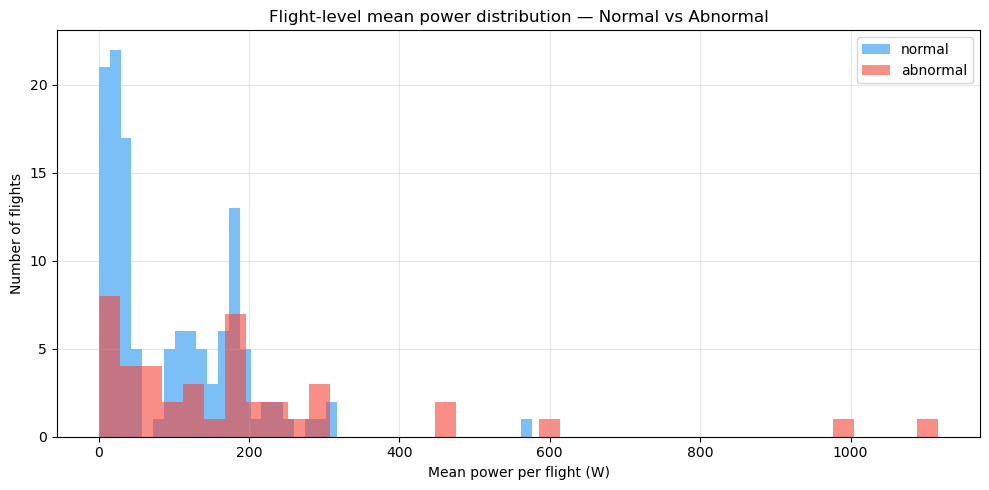

In [63]:
required_cols = ["log_id", "dataset_label", "power_w"]
for col in required_cols:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")

flight_power_summary = (
    df.groupby(["log_id","dataset_label"], as_index=False)
      .agg(mean_power_w=("power_w","mean"))
)

plot_df = flight_power_summary.copy()
plot_df["dataset_label"] = pd.Categorical(
    plot_df["dataset_label"], categories=["normal","abnormal"]
)

fig, ax = plt.subplots(figsize=(10, 5))
for label, color in [("normal","#2196F3"), ("abnormal","#F44336")]:
    vals = plot_df[plot_df["dataset_label"]==label]["mean_power_w"]
    ax.hist(vals, bins=40, alpha=0.6, color=color, label=label, edgecolor="none")
ax.set_xlabel("Mean power per flight (W)")
ax.set_ylabel("Number of flights")
ax.set_title("Flight-level mean power distribution — Normal vs Abnormal")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "flight_power_distribution.png", dpi=150)
plt.show()

In [64]:
print(f"Dataset shape after cleaning: {df.shape}")
print(f"Flights: {df['log_id'].nunique()}")
print(df["dataset_label"].value_counts())

Dataset shape after cleaning: (971822, 378)
Flights: 168
dataset_label
normal      690380
abnormal    281442
Name: count, dtype: int64


## 19. Missing value report

In [65]:
MISSING_THRESHOLD = 80

missing_report = pd.DataFrame({
    "column"          : df.columns,
    "missing_count"   : df.isna().sum().values,
    "missing_percent" : df.isna().mean().values * 100,
    "data_type"       : df.dtypes.astype(str).values,
    "unique_values"   : df.nunique(dropna=True).values
}).sort_values("missing_percent", ascending=False).reset_index(drop=True)

print(f"Columns 100% missing : {(missing_report['missing_percent']==100).sum()}")
print(f"Columns >80% missing : {(missing_report['missing_percent']>MISSING_THRESHOLD).sum()}")
print(f"Columns 0% missing   : {(missing_report['missing_percent']==0).sum()}")
display(missing_report.head(50))
missing_report.to_csv(EDA_DIR / "03_missing_report.csv", index=False)

cols_to_remove_missing = set(
    missing_report[missing_report["missing_percent"] > MISSING_THRESHOLD]["column"].tolist()
)
print("\nColumns removed due to missing >80%:", len(cols_to_remove_missing))

Columns 100% missing : 247
Columns >80% missing : 342
Columns 0% missing   : 21


,column,missing_count,missing_percent,data_type,unique_values
0,vehicle_status__pre_flight_checks_pass,971822,100.0,float64,0
1,vehicle_gps_position__selected_rtcm_instance,971822,100.0,float64,0
2,vehicle_air_data__time_td,971822,100.0,float64,0
3,vehicle_air_data__rho,971822,100.0,float64,0
4,vehicle_air_data__baro_pressure_pa,971822,100.0,float64,0
5,vehicle_air_data__baro_temp_celcius,971822,100.0,float64,0
6,vehicle_air_data__baro_alt_meter,971822,100.0,float64,0
7,vehicle_gps_position__spoofing_state,971822,100.0,float64,0
8,vehicle_gps_position__rtcm_crc_failed,971822,100.0,float64,0
9,vehicle_attitude__delta_q_reset[1],971822,100.0,float64,0



Columns removed due to missing >80%: 342


## 20. Feature candidate filtering

In [66]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

candidate_features = []
for col in numeric_cols:
    if col in cols_to_exclude or col == target_col:
        continue
    if df[col].isna().mean() * 100 >= MISSING_THRESHOLD:
        continue
    if col in cols_to_remove_missing:
        continue
    if df[col].nunique(dropna=True) <= 1:
        continue
    candidate_features.append(col)

print(f"Candidate features: {len(candidate_features)}")
print(candidate_features)

Candidate features: 18
['battery_status__voltage_v', 'battery_status__voltage_filtered_v', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__cell_count', 'battery_status__warning', 'time_s', 'power_w', 'energy_increment_wh', 'cumulative_energy_wh', 'battery_status__system_source', 'battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]']


## 21. Correlation with target

In [67]:
correlation_rows = []
for col in candidate_features:
    temp = df[[col, target_col]].dropna()
    if len(temp) < 100:
        continue
    pearson  = temp[col].corr(temp[target_col], method="pearson")
    spearman = temp[col].corr(temp[target_col], method="spearman")
    correlation_rows.append({
        "column"            : col,
        "pearson_corr"      : pearson,
        "abs_pearson_corr"  : abs(pearson)  if pd.notna(pearson)  else np.nan,
        "spearman_corr"     : spearman,
        "abs_spearman_corr" : abs(spearman) if pd.notna(spearman) else np.nan
    })

correlation_report = (
    pd.DataFrame(correlation_rows)
    .sort_values("abs_pearson_corr", ascending=False)
    .reset_index(drop=True)
)
display(correlation_report.head(40))
correlation_report.to_csv(EDA_DIR / "04_correlation_with_target.csv", index=False)

,column,pearson_corr,abs_pearson_corr,spearman_corr,abs_spearman_corr
0,power_w,0.955721,0.955721,0.910448,0.910448
1,energy_increment_wh,0.955721,0.955721,0.910448,0.910448
2,battery_status__current_filtered_a,0.762080,0.762080,0.846616,0.846616
3,battery_status__current_a,0.750502,0.750502,0.837215,0.837215
4,cumulative_energy_wh,0.701561,0.701561,0.737583,0.737583
5,battery_status__discharged_mah,0.646661,0.646661,0.668416,0.668416
6,battery_status__cell_count,0.643427,0.643427,0.338155,0.338155
7,battery_status__voltage_filtered_v,0.584551,0.584551,0.118001,0.118001
8,battery_status__voltage_v,0.578298,0.578298,0.140859,0.140859
9,time_s,0.196575,0.196575,0.171968,0.171968


## 22. Mutual information

In [68]:
MI_SAMPLE = 100_000
mi_sample = df[candidate_features + [target_col]].dropna(subset=[target_col]).copy()
if len(mi_sample) > MI_SAMPLE:
    mi_sample = mi_sample.sample(n=MI_SAMPLE, random_state=42)

X_mi      = SimpleImputer(strategy="median").fit_transform(mi_sample[candidate_features])
y_mi      = mi_sample[target_col]
mi_scores = mutual_info_regression(X_mi, y_mi, random_state=42)

mi_report = (
    pd.DataFrame({"column": candidate_features, "mutual_information_score": mi_scores})
    .sort_values("mutual_information_score", ascending=False)
    .reset_index(drop=True)
)
display(mi_report.head(40))
mi_report.to_csv(EDA_DIR / "05_mutual_information.csv", index=False)

,column,mutual_information_score
0,cumulative_energy_wh,2.252150
1,battery_status__discharged_mah,2.218130
2,battery_status__current_filtered_a,2.155488
3,battery_status__voltage_filtered_v,1.850024
4,energy_increment_wh,1.704437
5,power_w,1.703585
6,battery_status__voltage_v,1.603076
7,battery_status__current_a,1.580515
8,battery_status__remaining,1.106727
9,time_s,1.058812


## 23. Select final features

In [ ]:
#Drop structurally missing and redundant columns
ALWAYS_EXCLUDE = [
    "battery_status__voltage_cell_v[0]",
    "battery_status__voltage_cell_v[1]",
    "battery_status__voltage_cell_v[2]",
    "battery_status__voltage_cell_v[3]",
    "energy_increment_wh",  # duplicate of power_w
]

top_corr_features = correlation_report.head(30)["column"].tolist()
top_mi_features   = mi_report.head(30)["column"].tolist()
valid_core        = [c for c in allowed_core_features if c in candidate_features]

final_feature_cols = sorted(
    set(valid_core + top_corr_features + top_mi_features)
    - set(ALWAYS_EXCLUDE)
)

print(f"Final feature count: {len(final_feature_cols)}")
for i, col in enumerate(final_feature_cols, 1):
    print(f"  {i:2d}. {col}")

Final feature count: 13
   1. battery_status__cell_count
   2. battery_status__current_a
   3. battery_status__current_filtered_a
   4. battery_status__discharged_mah
   5. battery_status__remaining
   6. battery_status__scale
   7. battery_status__system_source
   8. battery_status__voltage_filtered_v
   9. battery_status__voltage_v
  10. battery_status__warning
  11. cumulative_energy_wh
  12. power_w
  13. time_s


## 24. Review metadata features before removal

In [77]:
review_cols = [
    "battery_status__cell_count",
    "battery_status__scale",
    "battery_status__system_source",
    "battery_status__warning"
]

print("1. Value distribution")
for col in review_cols:
    if col not in df.columns:
        print(f"  {col}: NOT IN DATA")
        continue
    print("\n" + "="*60)
    print(col)
    print("Unique values:", df[col].nunique(dropna=True))
    print(df[col].value_counts(dropna=False).head(10))

print("\n2. Pearson correlation with target")
corr_results = []
for col in review_cols:
    if col not in df.columns:
        continue
    corr = df[col].corr(df[target_col])
    corr_results.append({"feature": col, "pearson_corr": corr})
display(pd.DataFrame(corr_results).sort_values("pearson_corr", ascending=False))

print("\n3. Mutual Information score")
display(mi_report[mi_report["column"].isin(review_cols)]
        .sort_values("mutual_information_score", ascending=False))

1. Value distribution

battery_status__cell_count
Unique values: 5
battery_status__cell_count
3.0     683532
4.0     176295
6.0      78728
12.0     28370
0.0       4897
Name: count, dtype: int64

battery_status__scale
Unique values: 164359
battery_status__scale
1.000000    168169
1.072844     10832
1.072846      2526
1.000157        36
1.001675        30
1.000568        30
1.026662        30
1.026662        30
1.000063        30
1.027592        30
Name: count, dtype: int64

battery_status__system_source
Unique values: 2
battery_status__system_source
1.0    758939
NaN    151475
0.0     61408
Name: count, dtype: int64

battery_status__warning
Unique values: 4
battery_status__warning
0.0    960081
1.0      9236
3.0      2107
2.0       398
Name: count, dtype: int64

2. Pearson correlation with target


,feature,pearson_corr
0,battery_status__cell_count,0.643427
1,battery_status__scale,0.140607
2,battery_status__system_source,0.066537
3,battery_status__warning,0.023974



3. Mutual Information score


,column,mutual_information_score
10,battery_status__scale,1.045216
11,battery_status__cell_count,0.531103
16,battery_status__system_source,0.141678
17,battery_status__warning,0.035277


## 25. Remove weak features

In [78]:
cols_to_remove = [
    "battery_status__system_source",
    "battery_status__warning"
]

final_feature_cols = [c for c in final_feature_cols if c not in cols_to_remove]

print("Removed:", cols_to_remove)
print("Updated final feature count:", len(final_feature_cols))
display(pd.DataFrame({
    "No.": range(1, len(final_feature_cols)+1),
    "Final Feature": final_feature_cols
}))

Removed: ['battery_status__system_source', 'battery_status__warning']
Updated final feature count: 11


,No.,Final Feature
0,1,battery_status__cell_count
1,2,battery_status__current_a
2,3,battery_status__current_filtered_a
3,4,battery_status__discharged_mah
4,5,battery_status__remaining
5,6,battery_status__scale
6,7,battery_status__voltage_filtered_v
7,8,battery_status__voltage_v
8,9,cumulative_energy_wh
9,10,power_w


## 26. idle phase flag

In [79]:
df["is_idle"] = (df["power_w"] < 10).astype(np.float32)

## 27. 3-second rolling std of power

In [80]:
df["power_w_rolling_std_3s"] = (
    df.groupby("log_id")["power_w"]
    .transform(lambda x: x.rolling(30, min_periods=1).std().fillna(0))
)

for feat in ["is_idle", "power_w_rolling_std_3s"]:
    if feat not in final_feature_cols:
        final_feature_cols.append(feat)

## 28. Correlation matrix

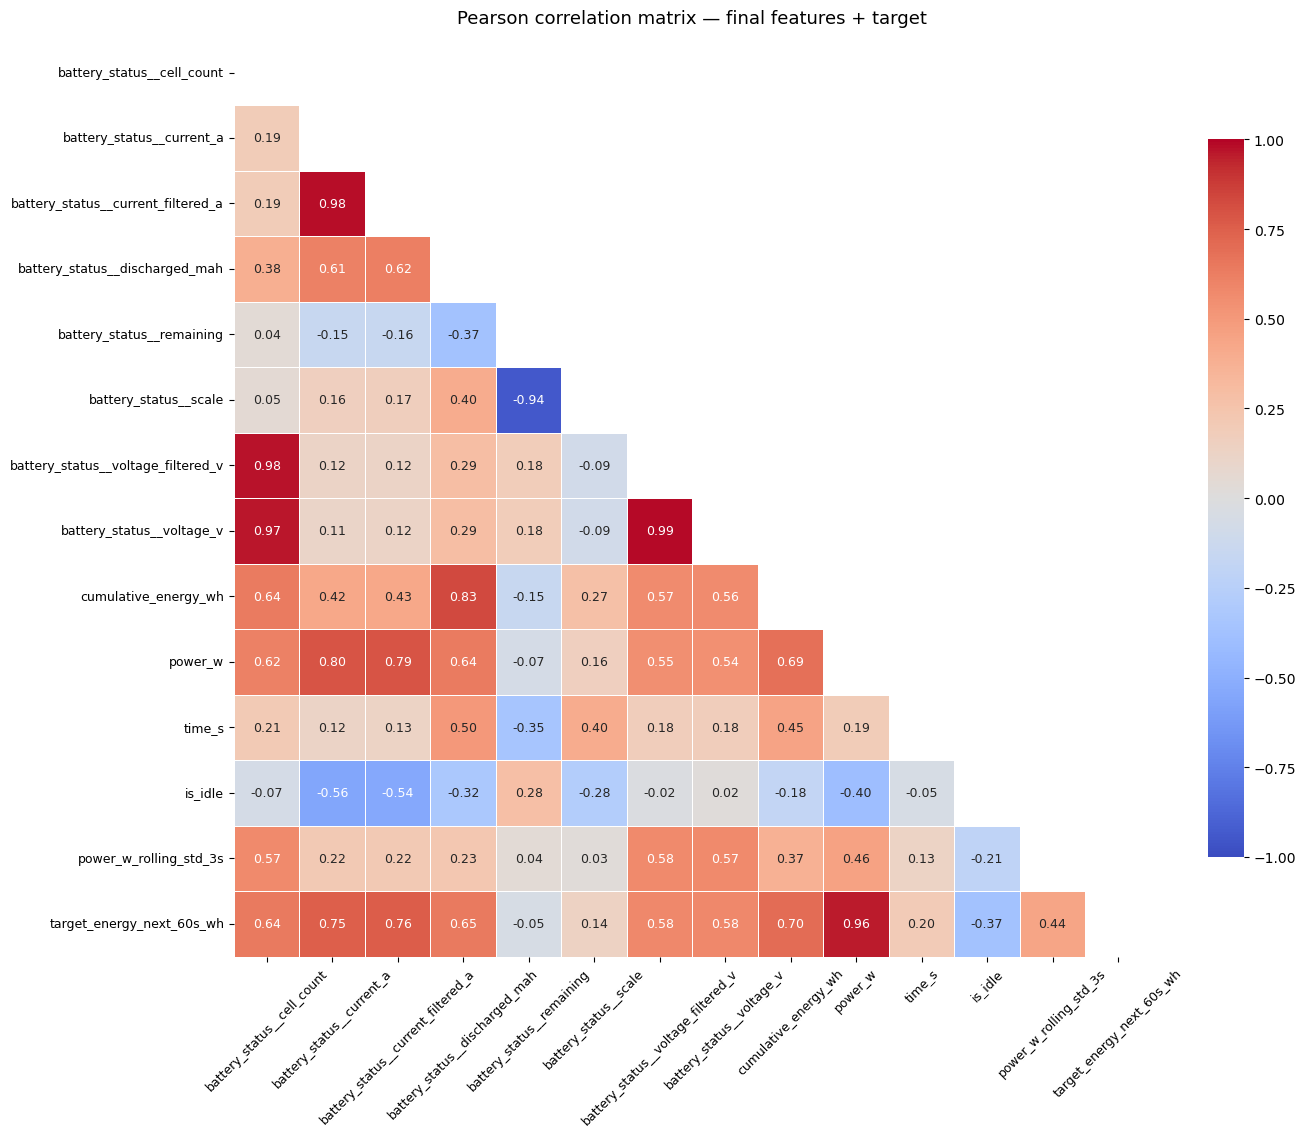


Top correlations with target:
power_w                               0.955721
battery_status__current_filtered_a    0.762080
battery_status__current_a             0.750502
cumulative_energy_wh                  0.701561
battery_status__discharged_mah        0.646661
battery_status__cell_count            0.643427
battery_status__voltage_filtered_v    0.584551
battery_status__voltage_v             0.578298
power_w_rolling_std_3s                0.441643
is_idle                               0.368814
time_s                                0.196575
battery_status__scale                 0.140607
battery_status__remaining             0.049614
Name: target_energy_next_60s_wh, dtype: float64


In [81]:
corr_cols   = final_feature_cols + [target_col]
corr_matrix = df[corr_cols].corr()
mask        = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr_matrix, ax=ax, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.7}, annot_kws={"size": 9})
ax.set_title("Pearson correlation matrix — final features + target",
             fontsize=13, pad=12)
ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.tick_params(axis="y", rotation=0,  labelsize=9)
plt.tight_layout()
plt.savefig(EDA_DIR / "correlation_matrix_final_features.png", dpi=150)
plt.show()

print("\nTop correlations with target:")
print(corr_matrix[target_col].drop(target_col).abs()
      .sort_values(ascending=False))

## 29. Save

In [82]:
final_cols = ["log_id", "dataset_label"] + final_feature_cols + [target_col]

missing_cols = [c for c in final_cols if c not in df.columns]
if missing_cols:
    print(f"WARNING — missing columns: {missing_cols}")
else:
    print("All columns present ✓")

clean_to_save = df[final_cols].copy()

CLEAN_PATH = PROJECT_DIR / "processed_10hz" / "clean_dataset_final_v2.csv"
clean_to_save.to_csv(CLEAN_PATH, index=False)

print(f"\nSaved: {CLEAN_PATH}")
print(f"Shape: {clean_to_save.shape}")
print(f"Columns: {clean_to_save.columns.tolist()}")
print(f"Flights: {clean_to_save['log_id'].nunique()}")
print(f"is_idle in features        : {'is_idle' in final_feature_cols}")
print(f"power_w_rolling_std_3s     : {'power_w_rolling_std_3s' in final_feature_cols}")

All columns present ✓

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/clean_dataset_final_v2.csv
Shape: (971822, 16)
Columns: ['log_id', 'dataset_label', 'battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'is_idle', 'power_w_rolling_std_3s', 'target_energy_next_60s_wh']
Flights: 168
is_idle in features        : True
power_w_rolling_std_3s     : True
